<a href="https://colab.research.google.com/github/fadzankerim/Network-Intrusion-Detection-System/blob/model/MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'UKLJUCI GPU')

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
# True = brza provjera da notebook radi (mali uzorak podataka, 3 epohe). Za prave rezultate False
BRZI_TEST = False

MAX_EPOCHS = 3 if BRZI_TEST else 100

In [2]:
#OSNOVNI KOD  POVEZIVANJE NA JEDISNTVEN DRIVE
import os, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
SEEDS = [42, 43, 44]
ATTACK_NAMES = ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic',
                'Normal', 'Reconnaissance', 'Shellcode', 'Worms']   # redoslijed iz LabelEncoder-a

# --- Google Drive (Colab) ---
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

def find_processed_dir():
    candidates = [Path('/content/drive/MyDrive/MPVI/Dataset/Processed'),
                  Path('/content/drive/MyDrive/Dataset/Processed'),
                  Path('Processed/Processed'), Path('Processed'), Path('Dataset/Processed')]
    for p in candidates:
        if (p / 'X_train.csv').exists():
            return p
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        found = list(drive_root.glob('**/Processed/X_train.csv'))
        if found:
            return found[0].parent
    raise FileNotFoundError('Folder sa X_train.csv nije pronađen – podesite putanju ručno.')

RESULTS_DIR = Path('/content/drive/MyDrive/MPVI/results') if Path('/content/drive/MyDrive').exists() else Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def load_data(path=None):
    """Učitava procesirane podatke. Vraća dict sa X_*, y_* (binarni), cat_* (attack_cat kod)."""
    P = Path(path) if path else find_processed_dir()
    d = {}
    for s in ('train', 'val', 'test'):
        d[f'X_{s}'] = pd.read_csv(P / f'X_{s}.csv').astype('float32')
        d[f'y_{s}'] = pd.read_csv(P / f'y_{s}_binary.csv').squeeze().astype(int).values
        d[f'cat_{s}'] = pd.read_csv(P / f'y_{s}_multi.csv').squeeze().astype(int).values
    d['features'] = json.load(open(P / 'feature_names.json'))
    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=d['y_train'])
    d['class_weight'] = {0: float(cw[0]), 1: float(cw[1])}
    print(f'📂 Podaci: {P}')
    for s in ('train', 'val', 'test'):
        print(f'   {s:5s}: {d[f"X_{s}"].shape}, napad = {d[f"y_{s}"].mean()*100:.1f}%')
    return d

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
    except ImportError:
        pass

def choose_threshold(y_val, scores_val):
    """Prag koji maksimizuje F1 na VALIDACIJI. Radi i za vjerovatnoće i za greške rekonstrukcije."""
    candidates = np.unique(np.quantile(scores_val, np.linspace(0.01, 0.99, 197)))
    f1s = [f1_score(y_val, (scores_val >= t).astype(int), zero_division=0) for t in candidates]
    return float(candidates[int(np.argmax(f1s))])

def evaluate(name, y_true, scores, threshold, cats=None, **extra):
    """scores = vjerovatnoća napada (ili greška rekonstrukcije); veći score = napad."""
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    res = {'model': name, 'threshold': float(threshold),
           'accuracy': float(accuracy_score(y_true, y_pred)),
           'precision': float(precision_score(y_true, y_pred, zero_division=0)),
           'recall': float(recall_score(y_true, y_pred)),
           'f1': float(f1_score(y_true, y_pred)),
           'roc_auc': float(roc_auc_score(y_true, scores)),
           'pr_auc': float(average_precision_score(y_true, scores)),
           'fpr': float(fp / (fp + tn)),
           'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}
    if cats is not None:
        per = pd.DataFrame({'cat': [ATTACK_NAMES[c] for c in cats], 'ok': y_pred == y_true})
        res['per_category'] = (per.groupby('cat')['ok'].mean() * 100).round(2).to_dict()
    res.update(extra)
    return res

def print_result(r):
    print(f"{r['model']}: acc={r['accuracy']:.4f} prec={r['precision']:.4f} rec={r['recall']:.4f} "
          f"f1={r['f1']:.4f} auc={r['roc_auc']:.4f} fpr={r['fpr']:.4f} (prag={r['threshold']:.4f})")
    if 'per_category' in r:
        print('   po kategoriji (%):', r['per_category'])

def save_result(r):
    fn = RESULTS_DIR / f"{r['model']}_seed{r.get('seed', 'na')}.json".replace(' ', '_')
    with open(fn, 'w') as f:
        json.dump(r, f, indent=2, ensure_ascii=False)
    print(f'💾 Sačuvano: {fn}')

def measure_inference(predict_fn, X, repeats=3):
    """Vraća prosječno vrijeme inferencije u mikrosekundama po zapisu."""
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); predict_fn(X); times.append(time.perf_counter() - t)
    return float(np.median(times) / len(X) * 1e6)

def plot_confusion(r, title=None):
    cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Napad']).plot(cmap='Blues', values_format='d')
    plt.title(title or r['model']); plt.show()

def plot_history(history, metric='auc'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, m in zip(axes, ['loss', metric]):
        ax.plot(history.history[m], label='train'); ax.plot(history.history[f'val_{m}'], label='val')
        ax.set_title(m); ax.set_xlabel('epoha'); ax.legend()
    plt.tight_layout(); plt.show()

data = load_data()
X_train, X_val, X_test = data['X_train'], data['X_val'], data['X_test']
y_train, y_val, y_test = data['y_train'], data['y_val'], data['y_test']
cat_train, cat_val, cat_test = data['cat_train'], data['cat_val'], data['cat_test']
# ======================================================================

Mounted at /content/drive
📂 Podaci: /content/drive/MyDrive/MPVI/Dataset/Processed
   train: (85689, 51), napad = 48.8%
   val  : (15122, 51), napad = 48.8%
   test : (82332, 51), napad = 55.1%


In [10]:
if BRZI_TEST:
    _r = np.random.RandomState(0)
    _i = _r.choice(len(X_train), 8000, replace=False)
    X_train, y_train, cat_train = X_train.iloc[_i].reset_index(drop=True), y_train[_i], cat_train[_i]
    _i = _r.choice(len(X_val), 6000, replace=False)
    X_val, y_val, cat_val = X_val.iloc[_i].reset_index(drop=True), y_val[_i], cat_val[_i]
    _i = _r.choice(len(X_test), 8000, replace=False)
    X_test, y_test, cat_test = X_test.iloc[_i].reset_index(drop=True), y_test[_i], cat_test[_i]
    print(' BRZI_TEST: koristi se mali uzorak podataka – rezultati NISU za dokumentaciju')

FIG_DIR = RESULTS_DIR.parent / 'figures' / 'exp2'
MODEL_DIR = RESULTS_DIR.parent / 'models' / 'exp2'
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Snima trenutnu sliku kao PNG u FIG_DIR i prikazuje je."""
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print(f'Rezultati: {RESULTS_DIR}\nSlike:     {FIG_DIR}\nModeli:    {MODEL_DIR}')
print(f'Class weights: {data["class_weight"]}')

Rezultati: /content/drive/MyDrive/MPVI/results
Slike:     /content/drive/MyDrive/MPVI/figures/exp2
Modeli:    /content/drive/MyDrive/MPVI/models/exp2
Class weights: {0: 0.9757122361139577, 1: 1.0255277897457993}


In [11]:
from tensorflow import keras
from tensorflow.keras import layers

def build_mlp(n_features, hidden=(256, 128, 64), dropout=0.3, batchnorm=True, lr=1e-3):
    inp = keras.Input(shape=(n_features,))
    x = inp
    for units in hidden:
        x = layers.Dense(units)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc'), 'accuracy'])
    return model

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10,
                                          restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5,
                                              patience=4, min_lr=1e-5)]

def train_mlp(seed=42, use_class_weight=True, batch_size=512, epochs=None, verbose=0, **kwargs):
    set_seed(seed)
    keras.backend.clear_session()
    model = build_mlp(X_train.shape[1], **kwargs)
    history = model.fit(X_train.values, y_train, validation_data=(X_val.values, y_val),
                        epochs=epochs or MAX_EPOCHS, batch_size=batch_size, verbose=verbose,
                        callbacks=callbacks(),
                        class_weight=data['class_weight'] if use_class_weight else None)
    return model, history

def predict(model, X):
    return model.predict(np.asarray(X), batch_size=4096, verbose=0).ravel()

**Arhitektura:** niz potpuno povezanih (Dense) slojeva. Svaki skriveni sloj ima redoslijed `Dense → BatchNormalization → ReLU → Dropout`.

| Element | Uloga |
|---|---|
| `Dense` | Uči linearne kombinacije ulaznih atributa |
| `BatchNormalization` | Normalizuje izlaze sloja tokom treninga, stabilizuje i ubrzava učenje |
| `ReLU` | Nelinearnost, `max(0, x)`. Ne pati od problema nestajućeg gradijenta kao sigmoid/tanh |
| `Dropout` | Nasumično "gasi" dio neurona tokom treninga, sprečava overfitting |
| `Dense(1, sigmoid)` | Izlaz je vjerovatnoća napada u opsegu (0, 1) |
| `binary_crossentropy` | Standardna funkcija gubitka za binarnu klasifikaciju |
| `Adam` | Adaptivni optimizator, robustan izbor learning rate-a |
| `EarlyStopping(val_auc)` | Zaustavlja trening kad val AUC prestane rasti 10 epoha i vraća najbolje težine |
| `ReduceLROnPlateau` | Prepolovi learning rate kad val AUC stagnira 4 epohe |

In [4]:
from tensorflow import keras
from tensorflow.keras import layers

def build_mlp(n_features, hidden=(256, 128, 64), dropout=0.3, batchnorm=True, lr=1e-3):
    inp = keras.Input(shape=(n_features,))
    x = inp
    for units in hidden:
        x = layers.Dense(units)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc'), 'accuracy'])
    return model

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10,
                                          restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5,
                                              patience=4, min_lr=1e-5)]

def train_mlp(seed=42, use_class_weight=True, batch_size=512, epochs=None, verbose=0, **kwargs):
    set_seed(seed)
    keras.backend.clear_session()
    model = build_mlp(X_train.shape[1], **kwargs)
    history = model.fit(X_train.values, y_train, validation_data=(X_val.values, y_val),
                        epochs=epochs or MAX_EPOCHS, batch_size=batch_size, verbose=verbose,
                        callbacks=callbacks(),
                        class_weight=data['class_weight'] if use_class_weight else None)
    return model, history

def predict(model, X):
    return model.predict(np.asarray(X), batch_size=4096, verbose=0).ravel()

In [12]:
BASE = dict(hidden=(256, 128, 64), dropout=0.3, batchnorm=True, lr=1e-3,
            use_class_weight=True, batch_size=512)

t0 = time.time()
base_model, base_history = train_mlp(seed=42, verbose=2, **BASE)
print(f'\n⏱️ Trening: {time.time() - t0:.1f} s, epoha: {len(base_history.history["loss"])}')
base_model.summary()

Epoch 1/100
168/168 - 17s - 100ms/step - accuracy: 0.8839 - auc: 0.9556 - loss: 0.2538 - val_accuracy: 0.9048 - val_auc: 0.9731 - val_loss: 0.2020 - learning_rate: 0.0010
Epoch 2/100
168/168 - 1s - 4ms/step - accuracy: 0.9055 - auc: 0.9722 - loss: 0.1949 - val_accuracy: 0.9098 - val_auc: 0.9760 - val_loss: 0.1856 - learning_rate: 0.0010
Epoch 3/100
168/168 - 1s - 4ms/step - accuracy: 0.9089 - auc: 0.9748 - loss: 0.1863 - val_accuracy: 0.9112 - val_auc: 0.9770 - val_loss: 0.1801 - learning_rate: 0.0010
Epoch 4/100
168/168 - 1s - 5ms/step - accuracy: 0.9115 - auc: 0.9760 - loss: 0.1825 - val_accuracy: 0.9132 - val_auc: 0.9780 - val_loss: 0.1767 - learning_rate: 0.0010
Epoch 5/100
168/168 - 1s - 5ms/step - accuracy: 0.9120 - auc: 0.9768 - loss: 0.1793 - val_accuracy: 0.9140 - val_auc: 0.9785 - val_loss: 0.1751 - learning_rate: 0.0010
Epoch 6/100
168/168 - 1s - 5ms/step - accuracy: 0.9129 - auc: 0.9774 - loss: 0.1771 - val_accuracy: 0.9152 - val_auc: 0.9788 - val_loss: 0.1739 - learning_ra

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 51)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,173 (653.02 KB)

 Trainable params: 55,425 (216.50 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 110,852 (433.02 KB)

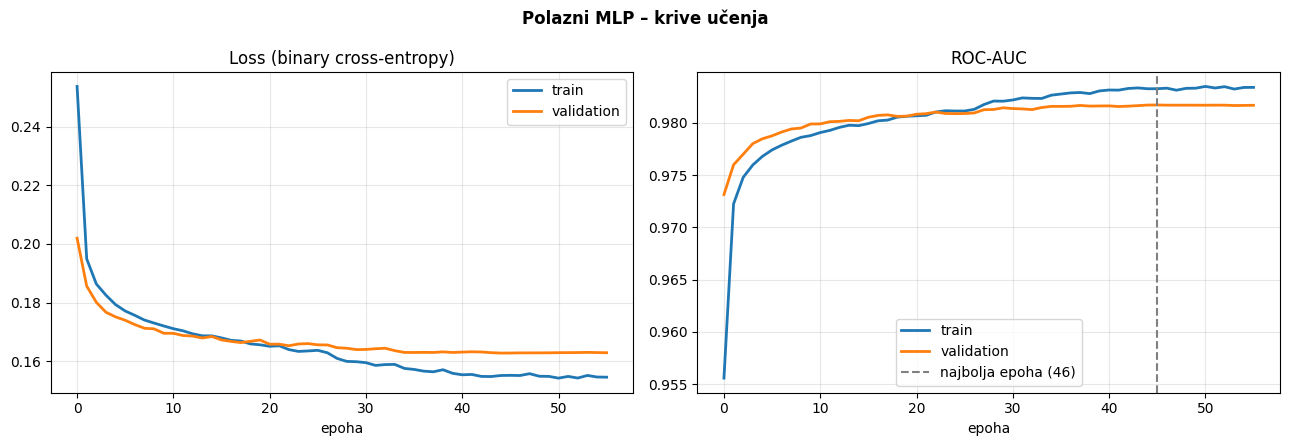

Polazni model – val AUC: 0.9820, val F1 (prag 0,5): 0.9202


In [13]:
def plot_learning_curves(history, title, name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, m, label in zip(axes, ['loss', 'auc'], ['Loss (binary cross-entropy)', 'ROC-AUC']):
        ax.plot(history.history[m], label='train', lw=2)
        ax.plot(history.history[f'val_{m}'], label='validation', lw=2)
        if m == 'auc':
            best = int(np.argmax(history.history['val_auc']))
            ax.axvline(best, color='gray', ls='--', label=f'najbolja epoha ({best + 1})')
        ax.set_title(label); ax.set_xlabel('epoha'); ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle(title, fontweight='bold')
    plt.tight_layout()
    save_fig(name)

plot_learning_curves(base_history, 'Polazni MLP – krive učenja', 'exp2_polazni_krive_ucenja')

p_val = predict(base_model, X_val)
print(f'Polazni model – val AUC: {roc_auc_score(y_val, p_val):.4f}, '
      f'val F1 (prag 0,5): {f1_score(y_val, (p_val >= 0.5).astype(int)):.4f}')

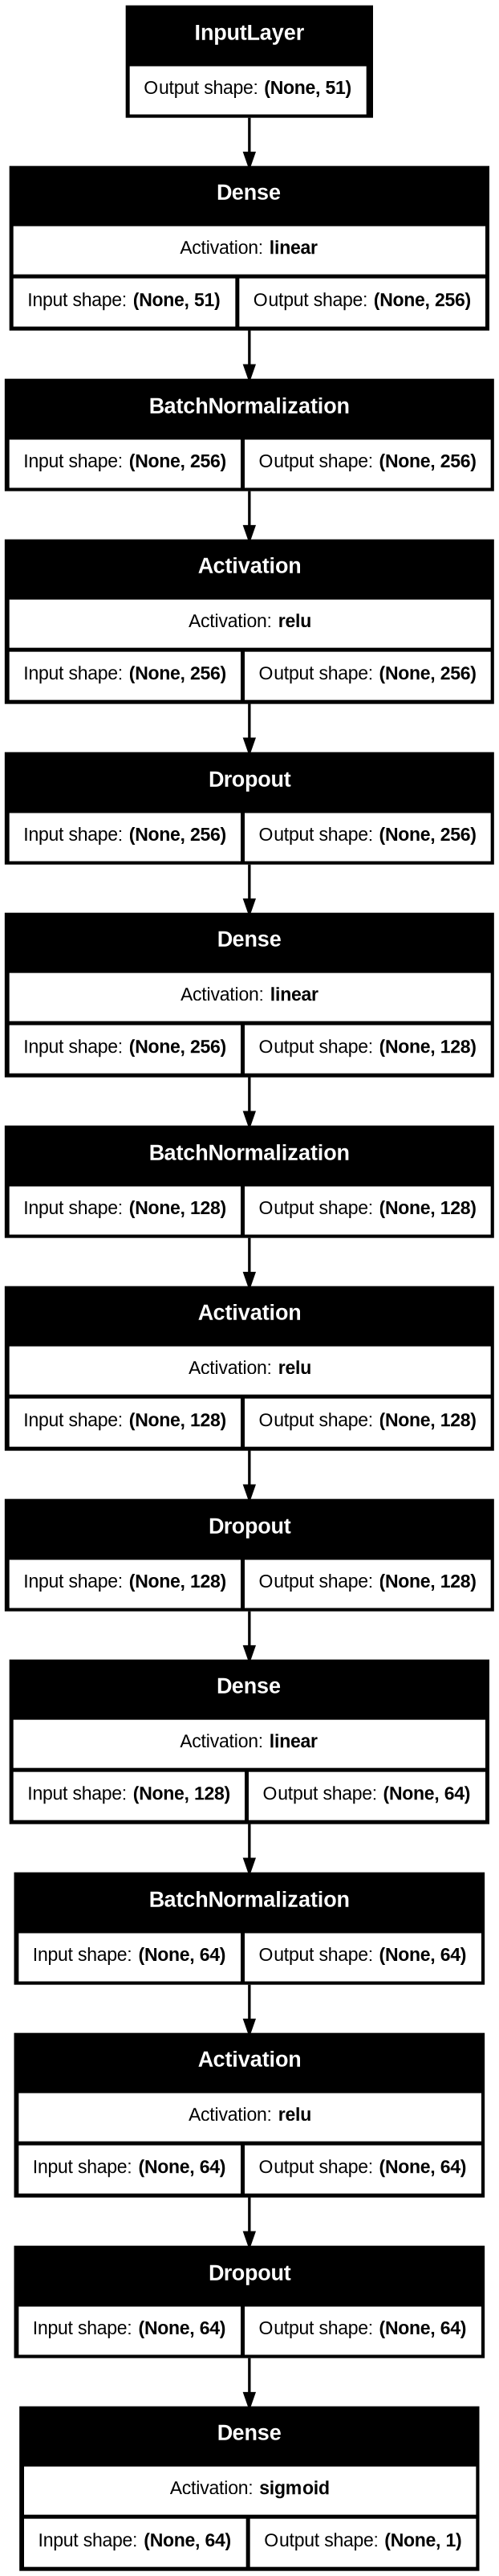

In [14]:
# Dijagram arhitekture (SLIKA 8.4) – zahtijeva pydot/graphviz, koji su na Colabu instalirani
try:
    keras.utils.plot_model(base_model, to_file=str(FIG_DIR / 'slika_8_4_arhitektura_mlp.png'),
                           show_shapes=True, show_layer_activations=True, dpi=120)
    from IPython.display import Image
    display(Image(str(FIG_DIR / 'slika_8_4_arhitektura_mlp.png')))
except Exception as e:
    print(f'ℹ️ plot_model nije uspio ({e}). Dijagram nacrtajte ručno prema model.summary().')

## 4. Ispitivanje hiperparametara – serije A–F

U svakoj seriji mijenja se **samo jedan** parametar, a ostali ostaju na polaznim vrijednostima. Tako se jasno vidi efekat svakog parametra posebno.

| Serija | Parametar | Vrijednosti | Pitanje |
|---|---|---|---|
| A | arhitektura | `(128, 64)`, `(256, 128, 64)`, `(512, 256, 128, 64)` | Da li dublja/šira mreža pomaže? |
| B | Dropout | 0,0 / 0,2 / 0,3 / 0,5 | Koliko regularizacije je potrebno? |
| C | BatchNorm | sa / bez | Da li BatchNorm stabilizuje trening? |
| D | learning rate | 1e-2 / 1e-3 / 1e-4 | Brzina i stabilnost konvergencije |
| E | class weight | sa / bez | Uticaj balansiranja klasa |
| F | batch size | 256 / 512 / 2048 | Brzina naspram kvaliteta |

**Kriterij:** val ROC-AUC (ne zavisi od praga). Sve serije koriste seed 42. **Test skup se ovdje ne koristi.**


In [15]:
SERIES = {
    'A': ('hidden', [(128, 64), (256, 128, 64), (512, 256, 128, 64)], 'arhitektura'),
    'B': ('dropout', [0.0, 0.2, 0.3, 0.5], 'Dropout'),
    'C': ('batchnorm', [True, False], 'BatchNorm'),
    'D': ('lr', [1e-2, 1e-3, 1e-4], 'learning rate'),
    'E': ('use_class_weight', [True, False], 'class weight'),
    'F': ('batch_size', [256, 512, 2048], 'batch size'),
}

run_cache = {}       # ista konfiguracija se ne trenira dvaput (polazna se pojavljuje u svakoj seriji)
series_tables = {}

def cfg_key(cfg):
    return json.dumps(cfg, sort_keys=True, default=str)

def run_config(cfg, seed=42):
    key = cfg_key(cfg)
    if key not in run_cache:
        t0 = time.time()
        model, hist = train_mlp(seed=seed, **cfg)
        p_val = predict(model, X_val)
        run_cache[key] = {
            'cfg': cfg, 'history': hist.history,
            'val_auc': roc_auc_score(y_val, p_val),
            'val_f1': f1_score(y_val, (p_val >= 0.5).astype(int)),
            'val_loss_min': float(np.min(hist.history['val_loss'])),
            'epohe': len(hist.history['loss']),
            'parametara': model.count_params(),
            'vrijeme_s': round(time.time() - t0, 1),
        }
    return run_cache[key]

def run_series(sid):
    param, values, label = SERIES[sid]
    rows = []
    for v in values:
        r = run_config({**BASE, param: v})
        rows.append({label: str(v), 'val_auc': round(r['val_auc'], 4), 'val_f1 (prag 0,5)': round(r['val_f1'], 4),
                     'min val_loss': round(r['val_loss_min'], 4), 'epohe': r['epohe'],
                     'parametara': r['parametara'], 'vrijeme (s)': r['vrijeme_s']})
        print(f'  {label} = {v}: val AUC = {r["val_auc"]:.4f} ({r["epohe"]} epoha, {r["vrijeme_s"]} s)')
    df = pd.DataFrame(rows)
    series_tables[sid] = df
    df.to_csv(RESULTS_DIR / f'exp2_serija_{sid}.csv', index=False)
    return df

def plot_series(sid):
    param, values, label = SERIES[sid]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for v in values:
        h = run_config({**BASE, param: v})['history']
        axes[0].plot(h['val_auc'], lw=2, label=f'{label} = {v}')
        axes[1].plot(h['val_loss'], lw=2, label=f'{label} = {v}')
    axes[0].set_title('Validation AUC'); axes[1].set_title('Validation loss')
    for ax in axes:
        ax.set_xlabel('epoha'); ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle(f'Serija {sid} – {label}', fontweight='bold')
    plt.tight_layout()
    save_fig(f'exp2_serija_{sid}')

# polazni model je već istreniran – dodaj ga u keš da se ne trenira ponovo
run_cache[cfg_key(BASE)] = {
    'cfg': BASE, 'history': base_history.history, 'val_auc': roc_auc_score(y_val, p_val),
    'val_f1': f1_score(y_val, (p_val >= 0.5).astype(int)),
    'val_loss_min': float(np.min(base_history.history['val_loss'])),
    'epohe': len(base_history.history['loss']), 'parametara': base_model.count_params(), 'vrijeme_s': None}

  arhitektura = (128, 64): val AUC = 0.9813 (73 epoha, 68.9 s)
  arhitektura = (256, 128, 64): val AUC = 0.9820 (56 epoha, None s)


  arhitektura = (512, 256, 128, 64): val AUC = 0.9822 (60 epoha, 76.1 s)


,arhitektura,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,"(128, 64)",0.9813,0.9184,0.1650,73,15745,68.9
1,"(256, 128, 64)",0.9820,0.9202,0.1627,56,56321,NaN
2,"(512, 256, 128, 64)",0.9822,0.9205,0.1629,60,203009,76.1


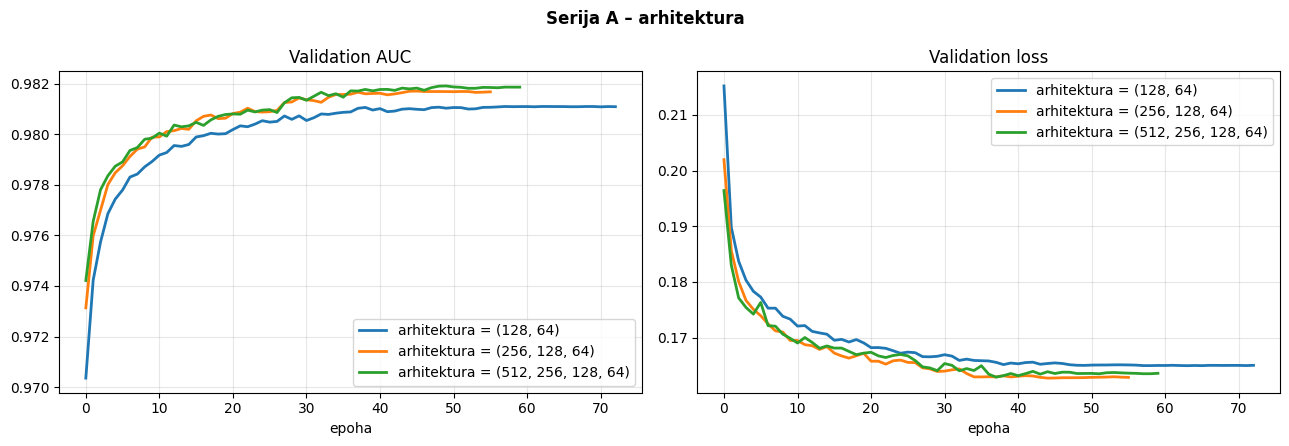

In [16]:
#SERIJA A DUBINA I SIRINA MREZE
display(run_series('A'))
plot_series('A')

  Dropout = 0.0: val AUC = 0.9815 (33 epoha, 37.5 s)
  Dropout = 0.2: val AUC = 0.9822 (66 epoha, 69.1 s)
  Dropout = 0.3: val AUC = 0.9820 (56 epoha, None s)
  Dropout = 0.5: val AUC = 0.9810 (49 epoha, 55.1 s)


,Dropout,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,0.0,0.9815,0.9192,0.1663,33,56321,37.5
1,0.2,0.9822,0.9193,0.1619,66,56321,69.1
2,0.3,0.9820,0.9202,0.1627,56,56321,NaN
3,0.5,0.9810,0.9185,0.1660,49,56321,55.1


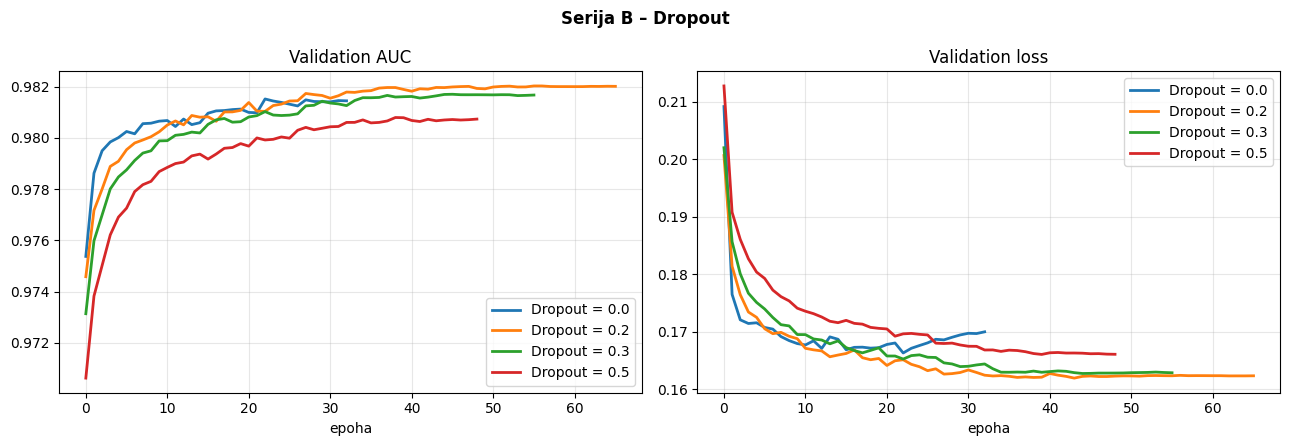

In [17]:
#SERIJA B DROPOUT
display(run_series('B'))
plot_series('B')

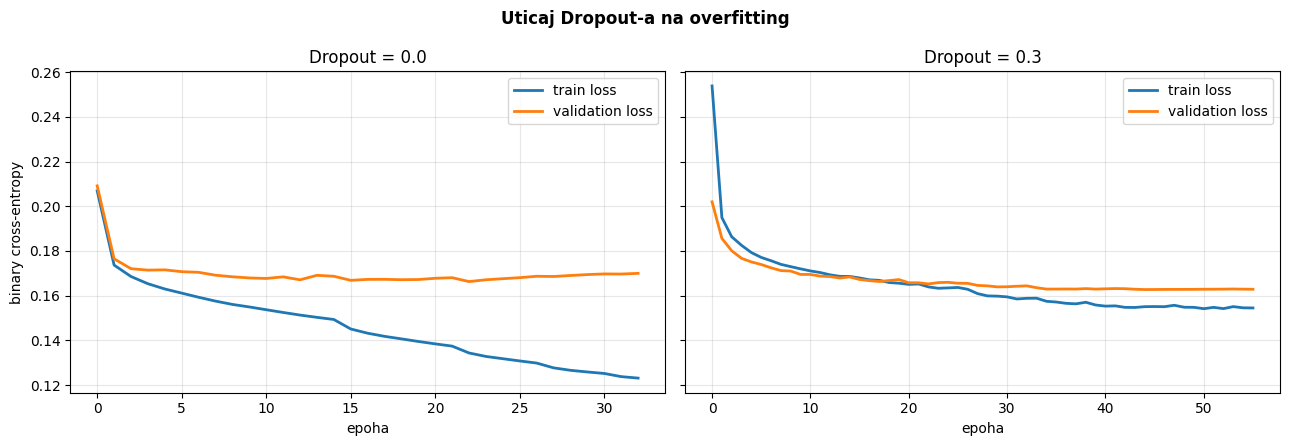

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, d in zip(axes, [0.0, 0.3]):
    h = run_config({**BASE, 'dropout': d})['history']
    ax.plot(h['loss'], lw=2, label='train loss')
    ax.plot(h['val_loss'], lw=2, label='validation loss')
    ax.set_title(f'Dropout = {d}'); ax.set_xlabel('epoha'); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel('binary cross-entropy')
plt.suptitle('Uticaj Dropout-a na overfitting', fontweight='bold')
plt.tight_layout()
save_fig('slika_8_6_dropout_poredjenje')

  BatchNorm = True: val AUC = 0.9820 (56 epoha, None s)
  BatchNorm = False: val AUC = 0.9824 (70 epoha, 62.2 s)


,BatchNorm,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,True,0.9820,0.9202,0.1627,56,56321,NaN
1,False,0.9824,0.9203,0.1623,70,54529,62.2


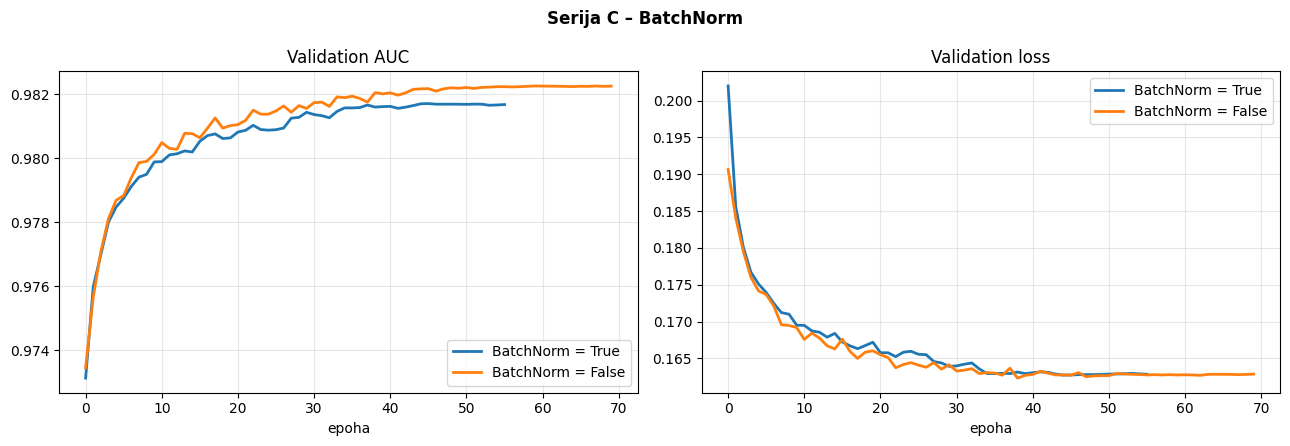

In [19]:
#SERIJA C BATCH NORMALIZACIJA
display(run_series('C'))
plot_series('C')

  learning rate = 0.01: val AUC = 0.9816 (62 epoha, 65.8 s)
  learning rate = 0.001: val AUC = 0.9820 (56 epoha, None s)
  learning rate = 0.0001: val AUC = 0.9808 (100 epoha, 96.2 s)


,learning rate,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,0.01,0.9816,0.9188,0.1650,62,56321,65.8
1,0.001,0.9820,0.9202,0.1627,56,56321,NaN
2,0.0001,0.9808,0.9186,0.1666,100,56321,96.2


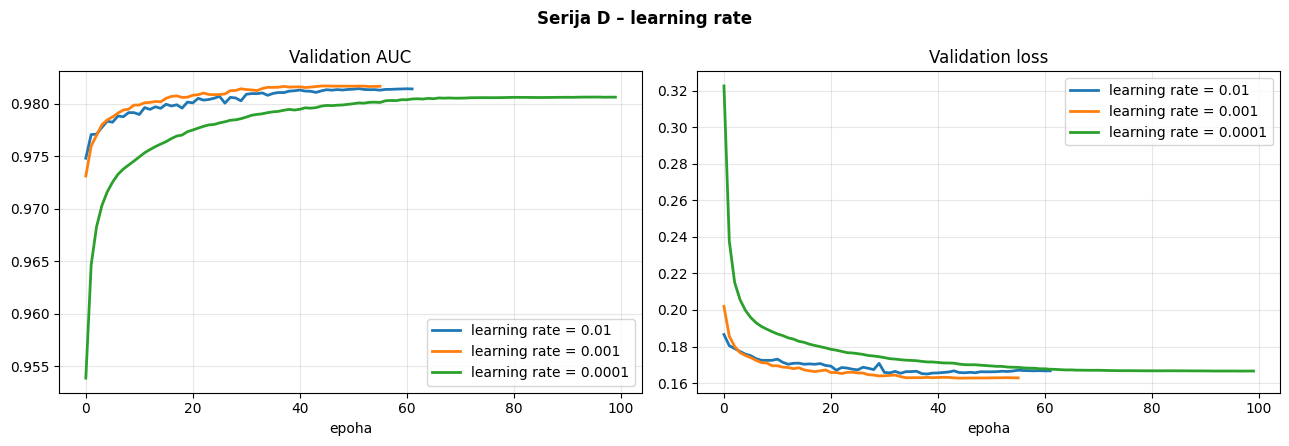

In [20]:
#SERIJA D LEARNING RATE
display(run_series('D'))
plot_series('D')

  class weight = True: val AUC = 0.9820 (56 epoha, None s)
  class weight = False: val AUC = 0.9821 (77 epoha, 76.3 s)


,class weight,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,True,0.9820,0.9202,0.1627,56,56321,NaN
1,False,0.9821,0.9205,0.1620,77,56321,76.3


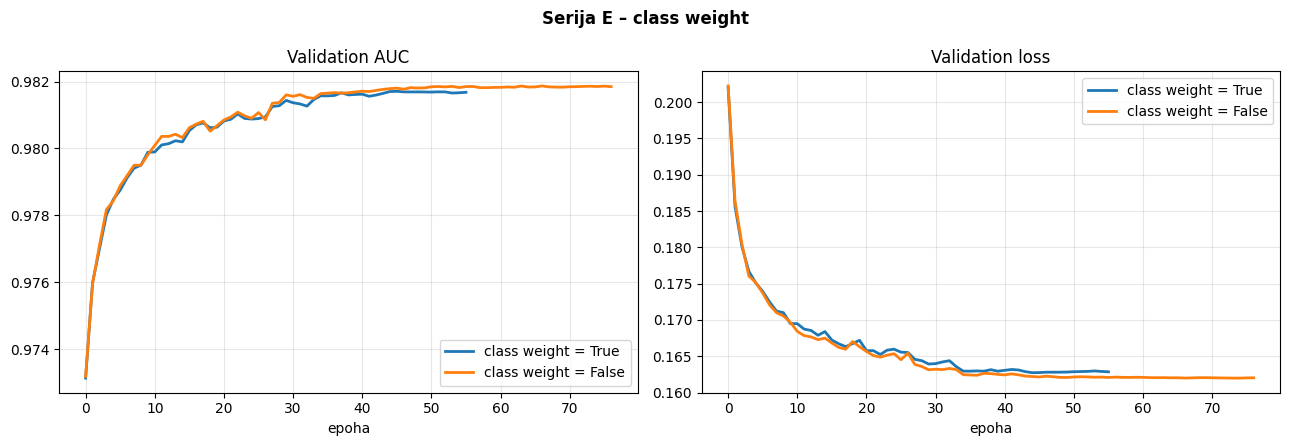

In [21]:
#SERIJA E ClASS WEIGHT
display(run_series('E'))
plot_series('E')

  batch size = 256: val AUC = 0.9821 (74 epoha, 123.0 s)
  batch size = 512: val AUC = 0.9820 (56 epoha, None s)
  batch size = 2048: val AUC = 0.9818 (100 epoha, 53.5 s)


,batch size,val_auc,"val_f1 (prag 0,5)",min val_loss,epohe,parametara,vrijeme (s)
0,256,0.9821,0.9205,0.1630,74,56321,123.0
1,512,0.9820,0.9202,0.1627,56,56321,NaN
2,2048,0.9818,0.9188,0.1629,100,56321,53.5


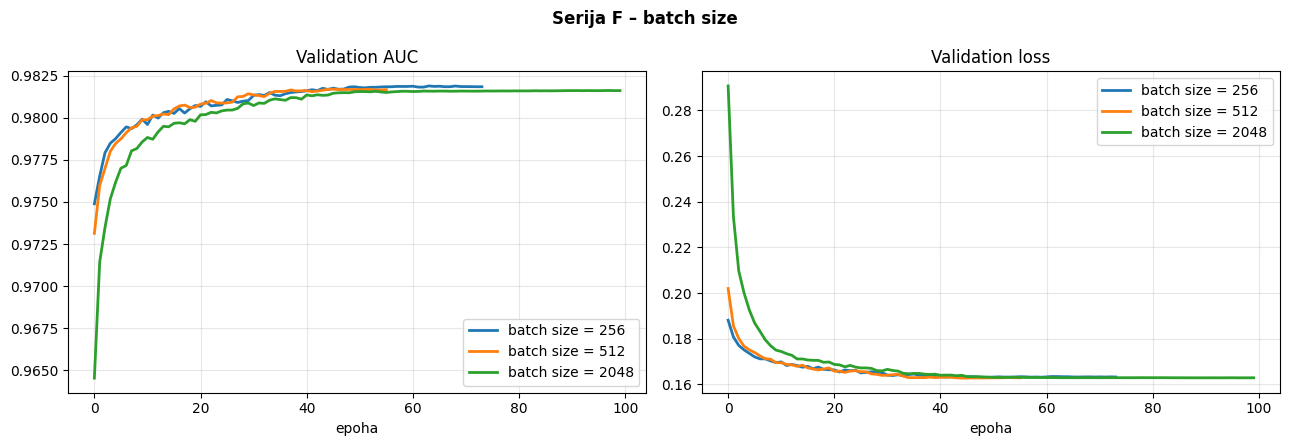

In [22]:
#SERIJA F BATCH SIZE
display(run_series('F'))
plot_series('F')

,serija,parametar,vrijednost,val_auc,"val_f1 (prag 0,5)",epohe,parametara
0,A,arhitektura,"(128, 64)",0.9813,0.9184,73,15745
1,A,arhitektura,"(256, 128, 64)",0.9820,0.9202,56,56321
2,A,arhitektura,"(512, 256, 128, 64)",0.9822,0.9205,60,203009
3,B,Dropout,0.0,0.9815,0.9192,33,56321
4,B,Dropout,0.2,0.9822,0.9193,66,56321
5,B,Dropout,0.3,0.9820,0.9202,56,56321
6,B,Dropout,0.5,0.9810,0.9185,49,56321
7,C,BatchNorm,True,0.9820,0.9202,56,56321
8,C,BatchNorm,False,0.9824,0.9203,70,54529
9,D,learning rate,0.01,0.9816,0.9188,62,56321


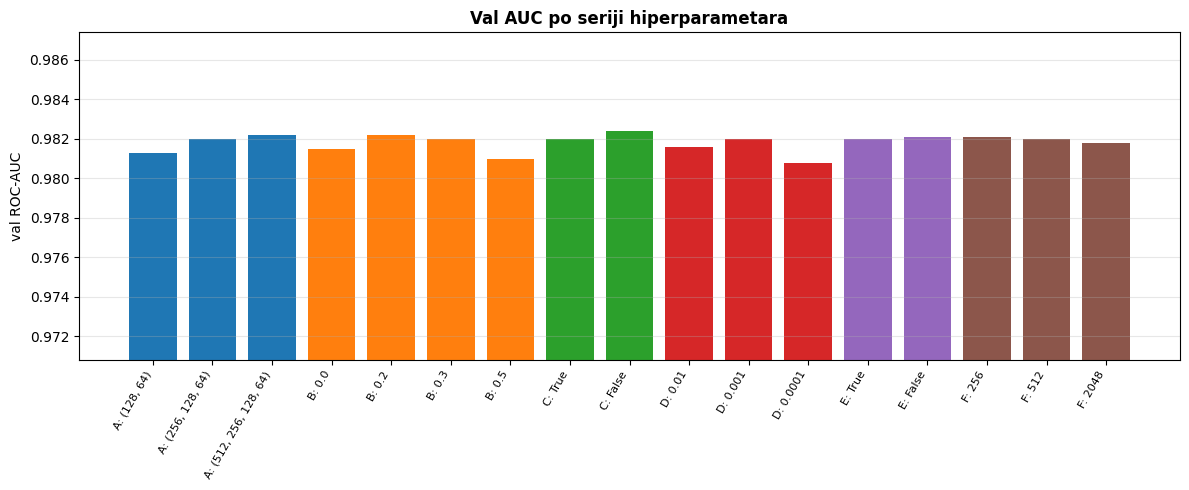

In [23]:
# Zbirna tabela svih serija (Tabela 8.6 u dokumentaciji)
summary_rows = []
for sid, (param, values, label) in SERIES.items():
    df = series_tables[sid]
    for _, row in df.iterrows():
        summary_rows.append({'serija': sid, 'parametar': label, 'vrijednost': row[label],
                             'val_auc': row['val_auc'], 'val_f1 (prag 0,5)': row['val_f1 (prag 0,5)'],
                             'epohe': row['epohe'], 'parametara': row['parametara']})
tabela_8_6 = pd.DataFrame(summary_rows)
tabela_8_6.to_csv(RESULTS_DIR / 'exp2_tabela_8_6_serije.csv', index=False)
display(tabela_8_6)

plt.figure(figsize=(12, 5))
labels = [f"{r['serija']}: {r['vrijednost']}" for _, r in tabela_8_6.iterrows()]
colors = plt.cm.tab10([list(SERIES).index(s) for s in tabela_8_6['serija']])
plt.bar(range(len(tabela_8_6)), tabela_8_6['val_auc'], color=colors)
plt.xticks(range(len(tabela_8_6)), labels, rotation=60, ha='right', fontsize=8)
lo = tabela_8_6['val_auc'].min()
plt.ylim(max(0.5, lo - 0.01), min(1.0, tabela_8_6['val_auc'].max() + 0.005))
plt.ylabel('val ROC-AUC'); plt.title('Val AUC po seriji hiperparametara', fontweight='bold')
plt.grid(axis='y', alpha=0.3); plt.tight_layout()
save_fig('exp2_serije_zbirno')

In [24]:
best_per_series = {}
for sid, (param, values, label) in SERIES.items():
    scores = [run_config({**BASE, param: v})['val_auc'] for v in values]
    best_per_series[param] = values[int(np.argmax(scores))]
    print(f'Serija {sid} ({label}): najbolje = {best_per_series[param]}  (val AUC {max(scores):.4f})')

combined = {**BASE, **best_per_series}
r_comb = run_config(combined)
print(f'\nKombinacija najboljih: {combined}\n   val AUC = {r_comb["val_auc"]:.4f}')

ranking = sorted(run_cache.values(), key=lambda r: r['val_auc'], reverse=True)
print('\nTop 5 konfiguracija po val AUC:')
for r in ranking[:5]:
    print(f"   {r['val_auc']:.4f}  {r['cfg']}  ({r['parametara']:,} parametara)")

Serija A (arhitektura): najbolje = (512, 256, 128, 64)  (val AUC 0.9822)
Serija B (Dropout): najbolje = 0.2  (val AUC 0.9822)
Serija C (BatchNorm): najbolje = False  (val AUC 0.9824)
Serija D (learning rate): najbolje = 0.001  (val AUC 0.9820)
Serija E (class weight): najbolje = False  (val AUC 0.9821)
Serija F (batch size): najbolje = 256  (val AUC 0.9821)

Kombinacija najboljih: {'hidden': (512, 256, 128, 64), 'dropout': 0.2, 'batchnorm': False, 'lr': 0.001, 'use_class_weight': False, 'batch_size': 256}
   val AUC = 0.9819

Top 5 konfiguracija po val AUC:
   0.9824  {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': False, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}  (54,529 parametara)
   0.9822  {'hidden': (256, 128, 64), 'dropout': 0.2, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}  (56,321 parametara)
   0.9822  {'hidden': (512, 256, 128, 64), 'dropout': 0.3, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 

In [25]:
# Ručni izbor (opciono) – npr. ako je jednostavnija konfiguracija gotovo jednako dobra:
# FINAL_CONFIG_RUCNO = dict(hidden=(128, 64), dropout=0.3, batchnorm=True, lr=1e-3, use_class_weight=True, batch_size=512)
FINAL_CONFIG_RUCNO = None

# Automatski izbor: među konfiguracijama čiji je val AUC u okviru TOLERANCIJA od najboljeg
# bira se ona sa najmanje parametara (razlike manje od tolerancije su slučajne varijacije)
TOLERANCIJA = 0.001
best_auc = ranking[0]['val_auc']
kandidati = [r for r in ranking if r['val_auc'] >= best_auc - TOLERANCIJA]
izabrana = min(kandidati, key=lambda r: (r['parametara'], -r['val_auc']))
print(f'Kandidati unutar {TOLERANCIJA} od najboljeg val AUC ({best_auc:.4f}): {len(kandidati)}')
for r in kandidati:
    print(f"   {r['val_auc']:.4f}  {r['parametara']:>8,} param.  {r['cfg']}")

FINAL_CONFIG = FINAL_CONFIG_RUCNO or izabrana['cfg']
print('\n✅ FINALNA KONFIGURACIJA:')
for k, v in FINAL_CONFIG.items():
    print(f'   {k:17s} = {v}')
with open(RESULTS_DIR / 'exp2_finalna_konfiguracija.json', 'w') as f:
    json.dump(FINAL_CONFIG, f, indent=2, default=str)

Kandidati unutar 0.001 od najboljeg val AUC (0.9824): 10
   0.9824    54,529 param.  {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': False, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}
   0.9822    56,321 param.  {'hidden': (256, 128, 64), 'dropout': 0.2, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}
   0.9822   203,009 param.  {'hidden': (512, 256, 128, 64), 'dropout': 0.3, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}
   0.9821    56,321 param.  {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': False, 'batch_size': 512}
   0.9821    56,321 param.  {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 256}
   0.9820    56,321 param.  {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': True, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}
   0.9819   199,169 param.  {'hidden': (512, 256

In [26]:
all_results, final_models, final_histories = [], {}, {}
scores_test_by_seed = {}

for seed in SEEDS:
    t0 = time.time()
    model, hist = train_mlp(seed=seed, **FINAL_CONFIG)
    train_time = time.time() - t0

    scores_val = predict(model, X_val)
    scores_test = predict(model, X_test)
    thr = choose_threshold(y_val, scores_val)
    infer_us = measure_inference(lambda X: model.predict(X, batch_size=4096, verbose=0), X_test.values)

    r = evaluate('MLP_final', y_test, scores_test, thr, cat_test,
                 seed=seed, train_time_s=round(train_time, 1), epohe=len(hist.history['loss']),
                 parametara=int(model.count_params()), inference_us=round(infer_us, 3),
                 val_auc=float(roc_auc_score(y_val, scores_val)),
                 config={k: (list(v) if isinstance(v, tuple) else v) for k, v in FINAL_CONFIG.items()})
    print_result(r)
    save_result(r)
    model.save(MODEL_DIR / f'mlp_final_seed{seed}.keras')

    all_results.append(r)
    final_models[seed], final_histories[seed], scores_test_by_seed[seed] = model, hist, scores_test

np.save(RESULTS_DIR / 'MLP_final_scores_test_seed42.npy', scores_test_by_seed[42])
print(' Skorovi (seed 42) sačuvani za zajednički ROC grafik')

MLP_final: acc=0.8632 prec=0.8077 rec=0.9864 f1=0.8882 auc=0.9813 fpr=0.2877 (prag=0.4677)
   po kategoriji (%): {'Analysis': 99.7, 'Backdoor': 99.66, 'DoS': 99.0, 'Exploits': 99.34, 'Fuzzers': 92.08, 'Generic': 99.96, 'Normal': 71.23, 'Reconnaissance': 99.74, 'Shellcode': 99.47, 'Worms': 100.0}
💾 Sačuvano: /content/drive/MyDrive/MPVI/results/MLP_final_seed42.json
MLP_final: acc=0.8624 prec=0.8094 rec=0.9812 f1=0.8871 auc=0.9805 fpr=0.2831 (prag=0.4919)
   po kategoriji (%): {'Analysis': 99.85, 'Backdoor': 99.83, 'DoS': 99.02, 'Exploits': 99.27, 'Fuzzers': 88.4, 'Generic': 99.95, 'Normal': 71.69, 'Reconnaissance': 99.66, 'Shellcode': 99.21, 'Worms': 100.0}
💾 Sačuvano: /content/drive/MyDrive/MPVI/results/MLP_final_seed43.json
MLP_final: acc=0.8635 prec=0.8112 rec=0.9803 f1=0.8878 auc=0.9807 fpr=0.2795 (prag=0.5015)
   po kategoriji (%): {'Analysis': 99.85, 'Backdoor': 99.83, 'DoS': 99.17, 'Exploits': 99.34, 'Fuzzers': 87.53, 'Generic': 99.94, 'Normal': 72.05, 'Reconnaissance': 99.63, 'S

In [27]:
# Tabela 8.7 – finalni rezultati (prosjek ± std preko 3 seed-a)
metric_cols = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'fpr',
               'val_auc', 'epohe', 'train_time_s', 'inference_us']
res_df = pd.DataFrame(all_results)
display(res_df[['seed'] + metric_cols].round(4))

tabela_8_7 = pd.DataFrame({'prosjek': res_df[metric_cols].mean(), 'std': res_df[metric_cols].std()}).round(4)
tabela_8_7['prikaz'] = tabela_8_7['prosjek'].map('{:.4f}'.format) + ' ± ' + tabela_8_7['std'].map('{:.4f}'.format)
tabela_8_7.to_csv(RESULTS_DIR / 'exp2_tabela_8_7_finalni_rezultati.csv')
display(tabela_8_7)

per_cat_df = pd.DataFrame([r['per_category'] for r in all_results], index=[f'seed {r["seed"]}' for r in all_results])
per_cat_df.loc['prosjek'] = per_cat_df.mean()
print('Tačnost po kategoriji (%):')
display(per_cat_df.round(2))

,seed,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,val_auc,epohe,train_time_s,inference_us
0,42,0.8632,0.8077,0.9864,0.8882,0.9813,0.9859,0.2877,0.9824,70,65.4,1.844
1,43,0.8624,0.8094,0.9812,0.8871,0.9805,0.9855,0.2831,0.9824,69,63.4,2.363
2,44,0.8635,0.8112,0.9803,0.8878,0.9807,0.9859,0.2795,0.9822,71,65.1,2.198


,prosjek,std,prikaz
accuracy,0.8631,0.0006,0.8631 ± 0.0006
precision,0.8094,0.0018,0.8094 ± 0.0018
recall,0.9826,0.0033,0.9826 ± 0.0033
f1,0.8877,0.0006,0.8877 ± 0.0006
roc_auc,0.9808,0.0004,0.9808 ± 0.0004
pr_auc,0.9858,0.0002,0.9858 ± 0.0002
fpr,0.2834,0.0041,0.2834 ± 0.0041
val_auc,0.9823,0.0001,0.9823 ± 0.0001
epohe,70.0000,1.0000,70.0000 ± 1.0000
train_time_s,64.6333,1.0786,64.6333 ± 1.0786


Tačnost po kategoriji (%):


,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
seed 42,99.70,99.66,99.00,99.34,92.08,99.96,71.23,99.74,99.47,100.0
seed 43,99.85,99.83,99.02,99.27,88.40,99.95,71.69,99.66,99.21,100.0
seed 44,99.85,99.83,99.17,99.34,87.53,99.94,72.05,99.63,99.21,100.0
prosjek,99.80,99.77,99.06,99.32,89.34,99.95,71.66,99.68,99.30,100.0


In [28]:
# Tabela 8.5 – arhitektura finalnog modela
m42 = final_models[42]
arch_rows = []
for layer in m42.layers:
    cfg = layer.get_config()
    arch_rows.append({'sloj': layer.__class__.__name__,
                      'neurona / opis': cfg.get('units', cfg.get('rate', cfg.get('activation', ''))),
                      'aktivacija': cfg.get('activation', ''),
                      'izlaz': str(layer.output.shape),
                      'parametara': layer.count_params()})
tabela_8_5 = pd.DataFrame(arch_rows)
tabela_8_5.to_csv(RESULTS_DIR / 'exp2_tabela_8_5_arhitektura.csv', index=False)
display(tabela_8_5)
print(f'Ukupno parametara: {m42.count_params():,}')

,sloj,neurona / opis,aktivacija,izlaz,parametara
0,InputLayer,,,"(None, 51)",0
1,Dense,256,linear,"(None, 256)",13312
2,Activation,relu,relu,"(None, 256)",0
3,Dropout,0.3,,"(None, 256)",0
4,Dense,128,linear,"(None, 128)",32896
5,Activation,relu,relu,"(None, 128)",0
6,Dropout,0.3,,"(None, 128)",0
7,Dense,64,linear,"(None, 64)",8256
8,Activation,relu,relu,"(None, 64)",0
9,Dropout,0.3,,"(None, 64)",0


Ukupno parametara: 54,529


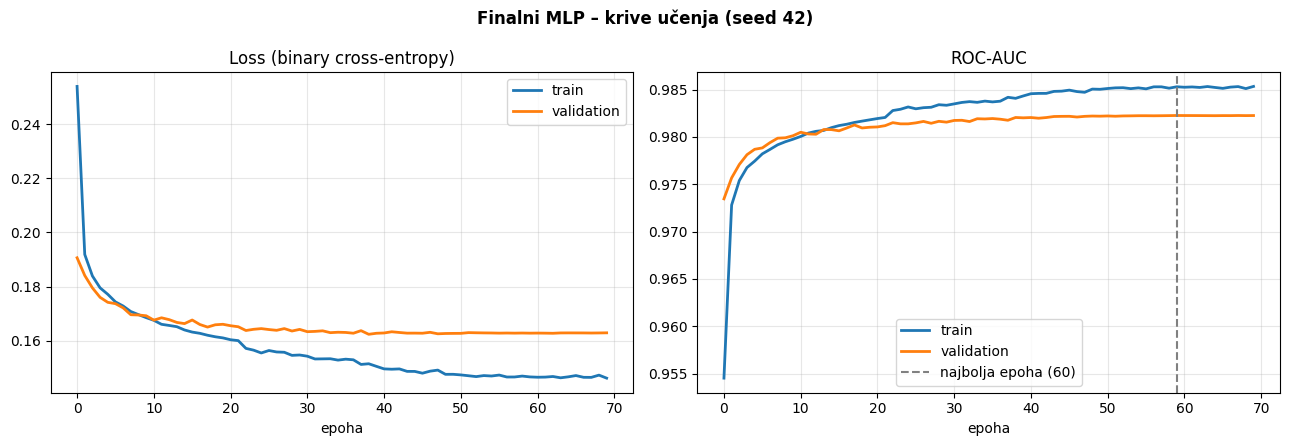

In [29]:
# SLIKA 8.5 – krive učenja finalnog modela (seed 42)
plot_learning_curves(final_histories[42], 'Finalni MLP – krive učenja (seed 42)', 'slika_8_5_krive_ucenja')

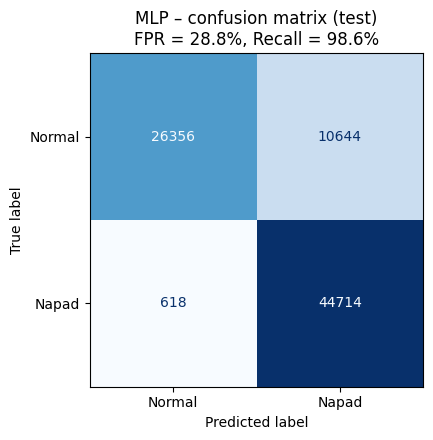

In [30]:
r42 = next(r for r in all_results if r['seed'] == 42)

# SLIKA 8.7 – confusion matrix
cm = np.array([[r42['tn'], r42['fp']], [r42['fn'], r42['tp']]])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Napad']).plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
ax.set_title(f'MLP – confusion matrix (test)\nFPR = {r42["fpr"]*100:.1f}%, Recall = {r42["recall"]*100:.1f}%')
plt.tight_layout()
save_fig('slika_8_7_confusion_matrix')

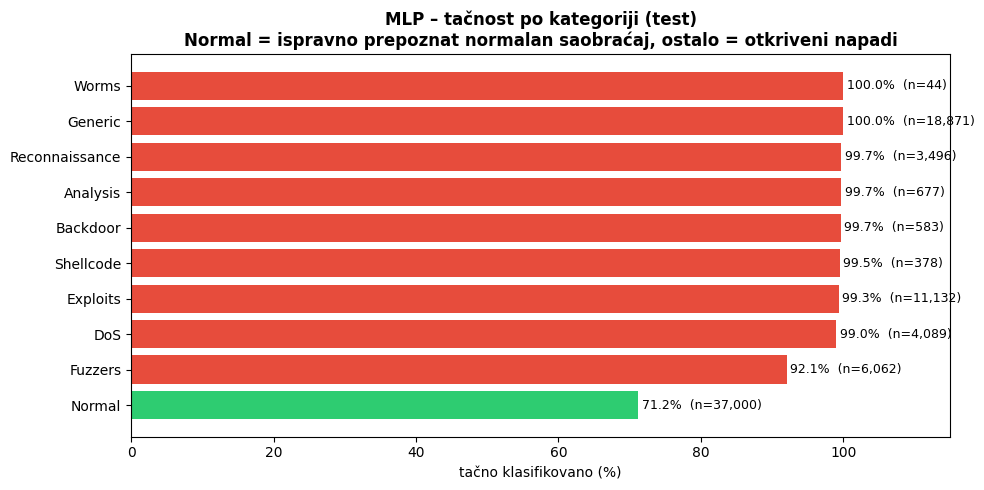

In [31]:
# Tačnost po kategoriji napada (test)
pc = pd.Series(r42['per_category']).sort_values()
counts = pd.Series([ATTACK_NAMES[c] for c in cat_test]).value_counts()
plt.figure(figsize=(10, 5))
bars = plt.barh(pc.index, pc.values, color=['#2ecc71' if k == 'Normal' else '#e74c3c' for k in pc.index])
for bar, k in zip(bars, pc.index):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
             f'{pc[k]:.1f}%  (n={counts.get(k, 0):,})', va='center', fontsize=9)
plt.xlim(0, 115); plt.xlabel('tačno klasifikovano (%)')
plt.title('MLP – tačnost po kategoriji (test)\nNormal = ispravno prepoznat normalan saobraćaj, ostalo = otkriveni napadi',
          fontweight='bold')
plt.tight_layout()
save_fig('exp2_tacnost_po_kategoriji')

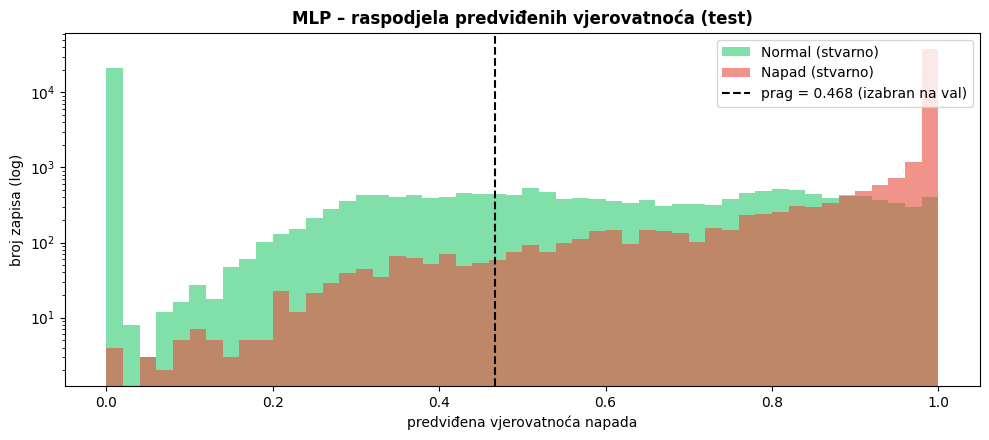

Lažni alarmi: 10,644; od toga sa vjerovatnoćom > 0,9: 17.1%


In [32]:
# SLIKA 8.8 – histogram predviđenih vjerovatnoća po klasi (test)
s42 = scores_test_by_seed[42]
plt.figure(figsize=(10, 4.5))
plt.hist(s42[y_test == 0], bins=50, alpha=0.6, label='Normal (stvarno)', color='#2ecc71', log=True)
plt.hist(s42[y_test == 1], bins=50, alpha=0.6, label='Napad (stvarno)', color='#e74c3c', log=True)
plt.axvline(r42['threshold'], color='black', ls='--', label=f'prag = {r42["threshold"]:.3f} (izabran na val)')
plt.xlabel('predviđena vjerovatnoća napada'); plt.ylabel('broj zapisa (log)')
plt.title('MLP – raspodjela predviđenih vjerovatnoća (test)', fontweight='bold')
plt.legend(); plt.tight_layout()
save_fig('slika_8_8_histogram_vjerovatnoca')

fp_scores = s42[(y_test == 0) & (s42 >= r42['threshold'])]
print(f'Lažni alarmi: {len(fp_scores):,}; od toga sa vjerovatnoćom > 0,9: {(fp_scores > 0.9).mean()*100:.1f}%')

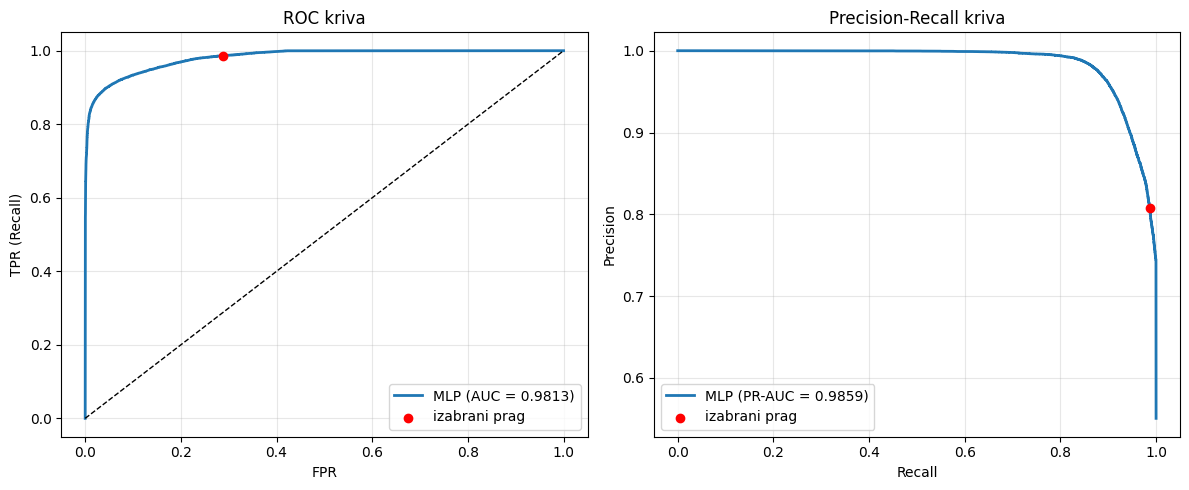

In [33]:
# ROC i Precision-Recall kriva (test, seed 42)
from sklearn.metrics import precision_recall_curve
fpr_c, tpr_c, _ = roc_curve(y_test, s42)
prec_c, rec_c, _ = precision_recall_curve(y_test, s42)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr_c, tpr_c, lw=2, label=f'MLP (AUC = {r42["roc_auc"]:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].scatter([r42['fpr']], [r42['recall']], color='red', zorder=5, label='izabrani prag')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR (Recall)'); axes[0].set_title('ROC kriva'); axes[0].legend()
axes[1].plot(rec_c, prec_c, lw=2, label=f'MLP (PR-AUC = {r42["pr_auc"]:.4f})')
axes[1].scatter([r42['recall']], [r42['precision']], color='red', zorder=5, label='izabrani prag')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-Recall kriva'); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('exp2_roc_pr_krive')

In [34]:
import glob
rows = [json.load(open(f)) for f in glob.glob(str(RESULTS_DIR / '*_final*_seed*.json'))]
comp = pd.DataFrame(rows)
cols = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'fpr', 'train_time_s']
agg = comp.groupby('model')[cols].agg(['mean', 'std']).round(4)
display(agg)
if comp['model'].nunique() == 1:
    print('ℹ️ Za sada postoje samo rezultati MLP-a – pokrenite ponovo kad ostali eksperimenti budu gotovi.')
else:
    print('Razlika je "stvarna" samo ako je veća od std vrijednosti oba modela.')

accuracy         precision          recall              f1          \
              mean     std      mean     std    mean     std    mean     std   
model                                                                          
MLP_final   0.8631  0.0006    0.8094  0.0018  0.9826  0.0033  0.8877  0.0006   

          roc_auc             fpr         train_time_s          
             mean     std    mean     std         mean     std  
model                                                           
MLP_final  0.9808  0.0004  0.2834  0.0041      64.6333  1.0786

ℹ️ Za sada postoje samo rezultati MLP-a – pokrenite ponovo kad ostali eksperimenti budu gotovi.


In [35]:
m = tabela_8_7['prosjek']; s = tabela_8_7['std']
print('=' * 70)
print('                 REZIME – EKSPERIMENT 2 (MLP)')
print('=' * 70)
if BRZI_TEST:
    print('⚠️  BRZI_TEST = True – OVI BROJEVI NISU ZA DOKUMENTACIJU')
print(f'Finalna konfiguracija: {FINAL_CONFIG}')
print(f'Broj parametara:       {final_models[42].count_params():,}')
print(f'Prosječan broj epoha:  {m["epohe"]:.1f} (early stopping)')
print(f'Vrijeme treniranja:    {m["train_time_s"]:.1f} ± {s["train_time_s"]:.1f} s')
print(f'Vrijeme inferencije:   {m["inference_us"]:.2f} µs po zapisu')
print('-' * 70)
print(f'Val AUC:               {m["val_auc"]:.4f} ± {s["val_auc"]:.4f}')
for k, name in [('accuracy', 'Test accuracy'), ('precision', 'Test precision'), ('recall', 'Test recall'),
                ('f1', 'Test F1'), ('roc_auc', 'Test ROC-AUC'), ('fpr', 'Test FPR')]:
    print(f'{name + ":":22s} {m[k]:.4f} ± {s[k]:.4f}')
print('-' * 70)
pc_mean = per_cat_df.loc['prosjek']
print(f'Najslabija kategorija napada: {pc_mean.drop("Normal").idxmin()} ({pc_mean.drop("Normal").min():.1f}%)')
print(f'Normal ispravno prepoznat:    {pc_mean["Normal"]:.1f}%')
print('=' * 70)

print('\nSerije – najbolja vrijednost po seriji:')
for sid, (param, values, label) in SERIES.items():
    print(f'  {sid} ({label}): {best_per_series[param]}')

                 REZIME – EKSPERIMENT 2 (MLP)
Finalna konfiguracija: {'hidden': (256, 128, 64), 'dropout': 0.3, 'batchnorm': False, 'lr': 0.001, 'use_class_weight': True, 'batch_size': 512}
Broj parametara:       54,529
Prosječan broj epoha:  70.0 (early stopping)
Vrijeme treniranja:    64.6 ± 1.1 s
Vrijeme inferencije:   2.13 µs po zapisu
----------------------------------------------------------------------
Val AUC:               0.9823 ± 0.0001
Test accuracy:         0.8631 ± 0.0006
Test precision:        0.8094 ± 0.0018
Test recall:           0.9826 ± 0.0033
Test F1:               0.8877 ± 0.0006
Test ROC-AUC:          0.9808 ± 0.0004
Test FPR:              0.2834 ± 0.0041
----------------------------------------------------------------------
Najslabija kategorija napada: Fuzzers (89.3%)
Normal ispravno prepoznat:    71.7%

Serije – najbolja vrijednost po seriji:
  A (arhitektura): (512, 256, 128, 64)
  B (Dropout): 0.2
  C (BatchNorm): False
  D (learning rate): 0.001
  E (class w